# Ensemble Methods


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import StackingRegressor, VotingClassifier, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

## Choose your own Regression

**Working together with your partner**, choose an interesting data set to fit *regression* models for, that is, a data set with a *quantitative* target variable and several feature variables. Could be a data set that: we have used in class, we have used on an assignment, a data set from your project, you used in another course, or you just find interesting! You'll work together with your partner to develop *regression* models to predict the *quantitative* target (so you need to decide on the data set and target variable together with your partner).

After you have decided on the data set and target variable:

- One partner should fit a linear regression model
- One partner should fit a k-nearest neighbors regression model

If you're using an example from earlier in the class, you can use a model you have already come up with or you can try something new. Note: you do NOT have to agree on the features included in your models.

After each partner has their model, **work together to combine your code and create two more models**:

- An ensemble model that uses **voting**
- An ensemble model that uses **stacking**

For each of the four models (linear regression, knn regression, voting ensemble, stacking ensemble)

1. Fit the model using the training data
1. Use the fitted model to predict the target for a few observations of your choice, and compare the predictions
1. Estimate the test RMSE using cross-validation, and compare the results

Which model seems to work best?


### Data and target

I am using the Ames Housing data. The regression target is `SalePrice` because it is quantitative. I used a focused set of eight house characteristics so the models stay easy to compare.

In [15]:
data_url = "https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt"

try:
    houses = pd.read_csv("AmesHousing.txt", sep="\t")
except FileNotFoundError:
    houses = pd.read_csv(data_url, sep="\t")

print("Original shape:", houses.shape)
houses.head()

Original shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,...,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,...,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,...,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,...,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,...,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,...,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


I removed the five homes with more than 4,000 square feet of above-ground living area. These are unusual compared with the rest of the data and have a large effect on the regression models.

In [16]:
houses = houses.loc[houses["Gr Liv Area"] <= 4000].copy()

features = [
    "Overall Qual",
    "Overall Cond",
    "Gr Liv Area",
    "Total Bsmt SF",
    "Garage Cars",
    "Full Bath",
    "Fireplaces",
    "Year Built",
]

X_regression = houses[features]
y_regression = houses["SalePrice"]

print("Shape after removing unusual homes:", houses.shape)
print("Missing values in the selected features:")
X_regression.isna().sum().to_frame("Missing")

Shape after removing unusual homes: (2925, 82)
Missing values in the selected features:


,Missing
Overall Qual,0
Overall Cond,0
Gr Liv Area,0
Total Bsmt SF,1
Garage Cars,1
Full Bath,0
Fireplaces,0
Year Built,0


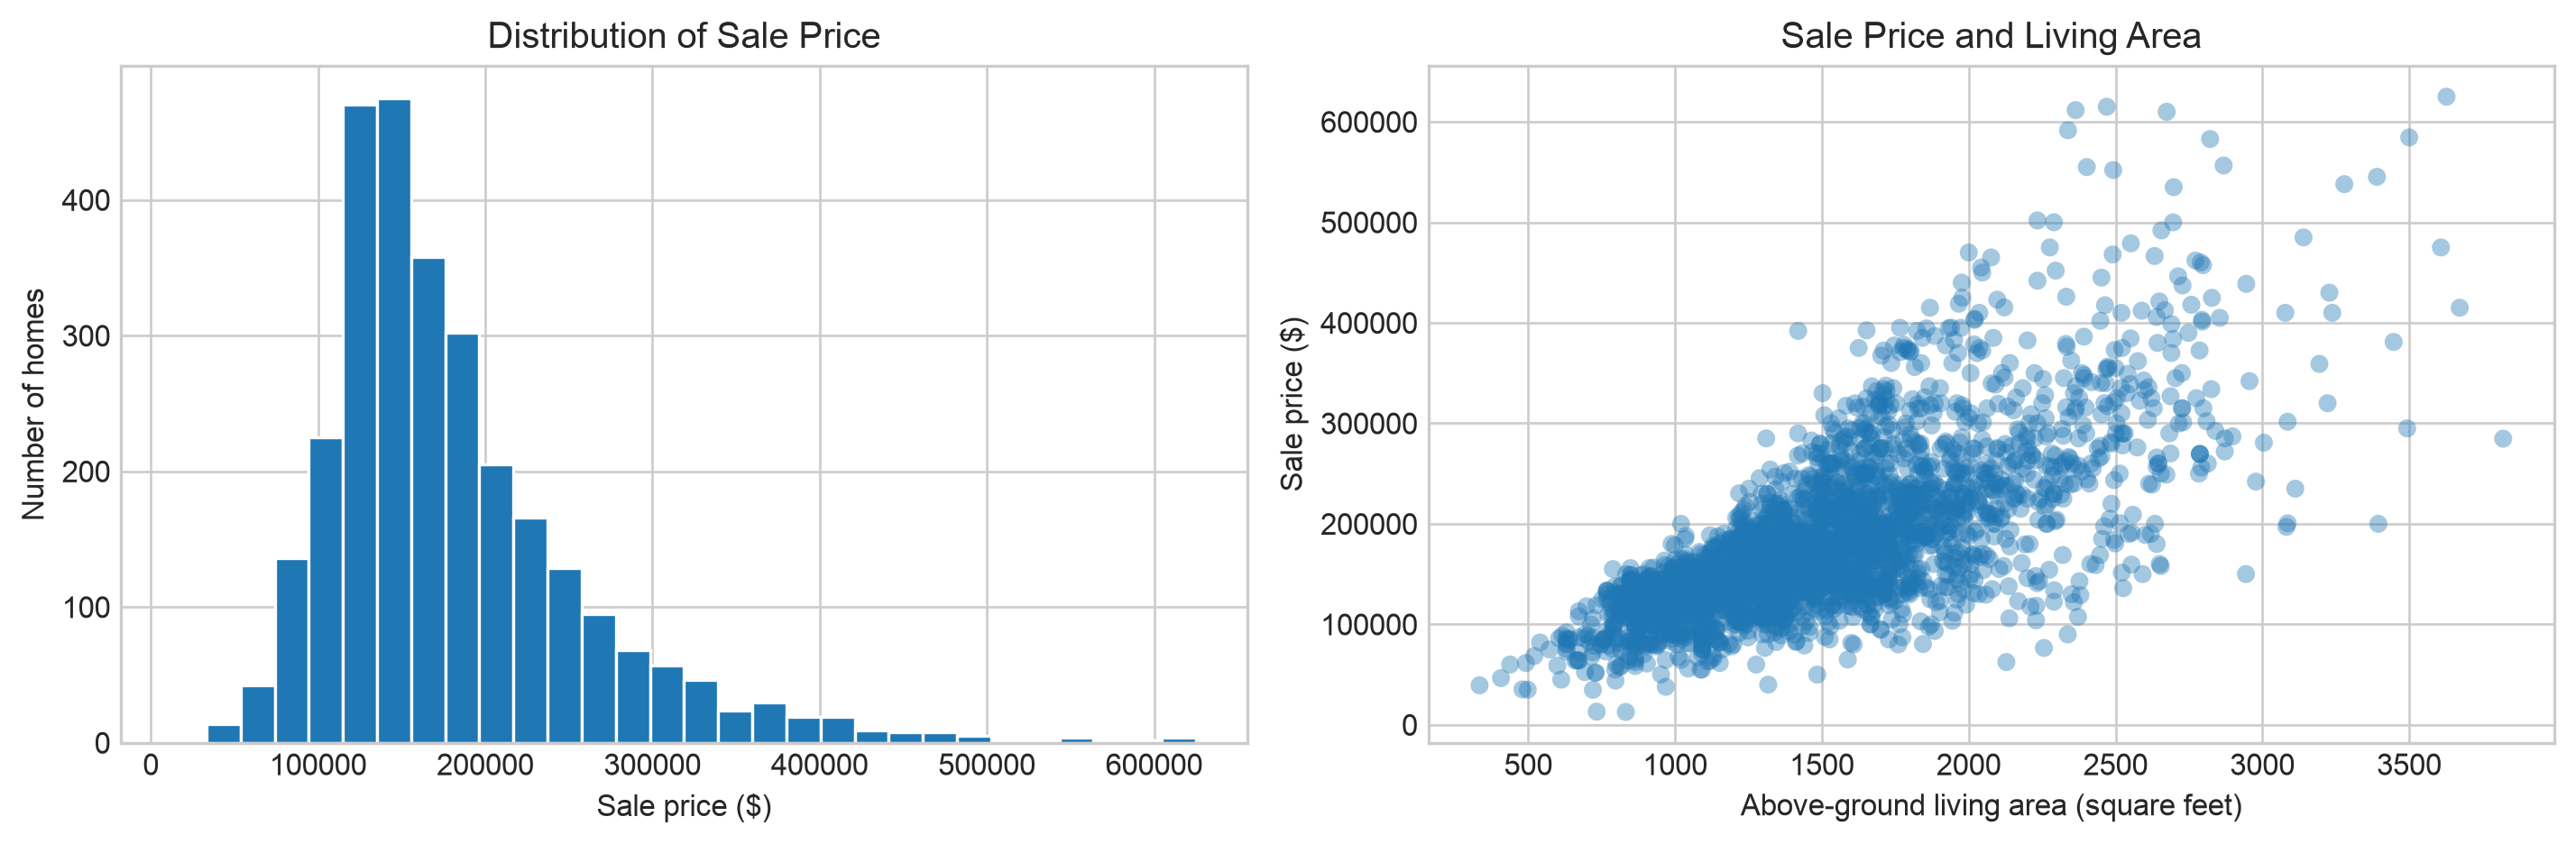

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y_regression, bins=30, edgecolor="white")
axes[0].set_title("Distribution of Sale Price")
axes[0].set_xlabel("Sale price ($)")
axes[0].set_ylabel("Number of homes")

axes[1].scatter(
    houses["Gr Liv Area"],
    y_regression,
    alpha=0.4,
    edgecolor="none",
)
axes[1].set_title("Sale Price and Living Area")
axes[1].set_xlabel("Above-ground living area (square feet)")
axes[1].set_ylabel("Sale price ($)")

plt.tight_layout()
plt.show()

Sale price is right-skewed, so there are a smaller number of very expensive homes. The scatterplot also shows that larger homes generally sell for more, although size does not explain every difference in price.

### Training data and preprocessing

In [18]:
price_groups = pd.qcut(y_regression, q=10, duplicates="drop")

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression,
    y_regression,
    test_size=0.20,
    random_state=42,
    stratify=price_groups,
)

print("Training observations:", len(X_reg_train))
print("Test observations:", len(X_reg_test))

Training observations: 2340
Test observations: 585


In [19]:
def make_regression_model(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
        ("model", model),
    ])


linear_model = make_regression_model(LinearRegression())

knn_regression_search = GridSearchCV(
    make_regression_model(KNeighborsRegressor()),
    {
        "model__n_neighbors": list(range(3, 32, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    cv=10,
    scoring="neg_root_mean_squared_error",
)
knn_regression_search.fit(X_reg_train, y_reg_train)

best_regression_k = knn_regression_search.best_params_["model__n_neighbors"]
best_regression_weights = knn_regression_search.best_params_["model__weights"]
best_regression_p = knn_regression_search.best_params_["model__p"]
knn_regression_model = make_regression_model(
    KNeighborsRegressor(
        n_neighbors=best_regression_k,
        weights=best_regression_weights,
        p=best_regression_p,
    )
)

print("Best kNN settings:", knn_regression_search.best_params_)

Best kNN settings: {'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'uniform'}


### Linear, kNN, voting, and stacking models

In [20]:
voting_regression_model = VotingRegressor([
    ("linear", linear_model),
    ("knn", knn_regression_model),
])

stacking_regression_model = StackingRegressor(
    estimators=[
        ("linear", linear_model),
        ("knn", knn_regression_model),
    ],
    final_estimator=Ridge(alpha=1.0),
    cv=5,
)

regression_models = {
    "Linear regression": linear_model,
    "kNN regression": knn_regression_model,
    "Voting regression": voting_regression_model,
    "Stacking regression": stacking_regression_model,
}

for model in regression_models.values():
    model.fit(X_reg_train, y_reg_train)

print("All four regression models are fitted.")

All four regression models are fitted.


### Predictions for a few homes

In [21]:
regression_examples = X_reg_test.iloc[:5]

regression_predictions = pd.DataFrame({
    "Actual sale price": y_reg_test.loc[regression_examples.index]
})

for name, model in regression_models.items():
    regression_predictions[name] = model.predict(regression_examples)

regression_predictions.round(0)

,Actual sale price,Linear regression,kNN regression,Voting regression,Stacking regression
2183,131750,119751.0,128678.0,124215.0,124121.0
1979,100000,57975.0,98782.0,78378.0,85230.0
88,127000,135675.0,141422.0,138549.0,138295.0
547,120000,152106.0,133128.0,142617.0,135257.0
705,129500,130253.0,123711.0,126982.0,122454.0


### Cross-validation RMSE

In [22]:
regression_cv = KFold(n_splits=10, shuffle=True, random_state=42)
regression_rows = []

for name, model in regression_models.items():
    scores = -cross_val_score(
        model,
        X_reg_train,
        y_reg_train,
        cv=regression_cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    regression_rows.append({
        "Model": name,
        "CV RMSE": scores.mean(),
        "RMSE standard deviation": scores.std(),
    })

regression_results = (
    pd.DataFrame(regression_rows)
    .sort_values("CV RMSE")
    .reset_index(drop=True)
)
regression_results.round(0)

,Model,CV RMSE,RMSE standard deviation
0,Stacking regression,25366.0,1384.0
1,kNN regression,26045.0,1379.0
2,Voting regression,26723.0,1371.0
3,Linear regression,32640.0,2034.0


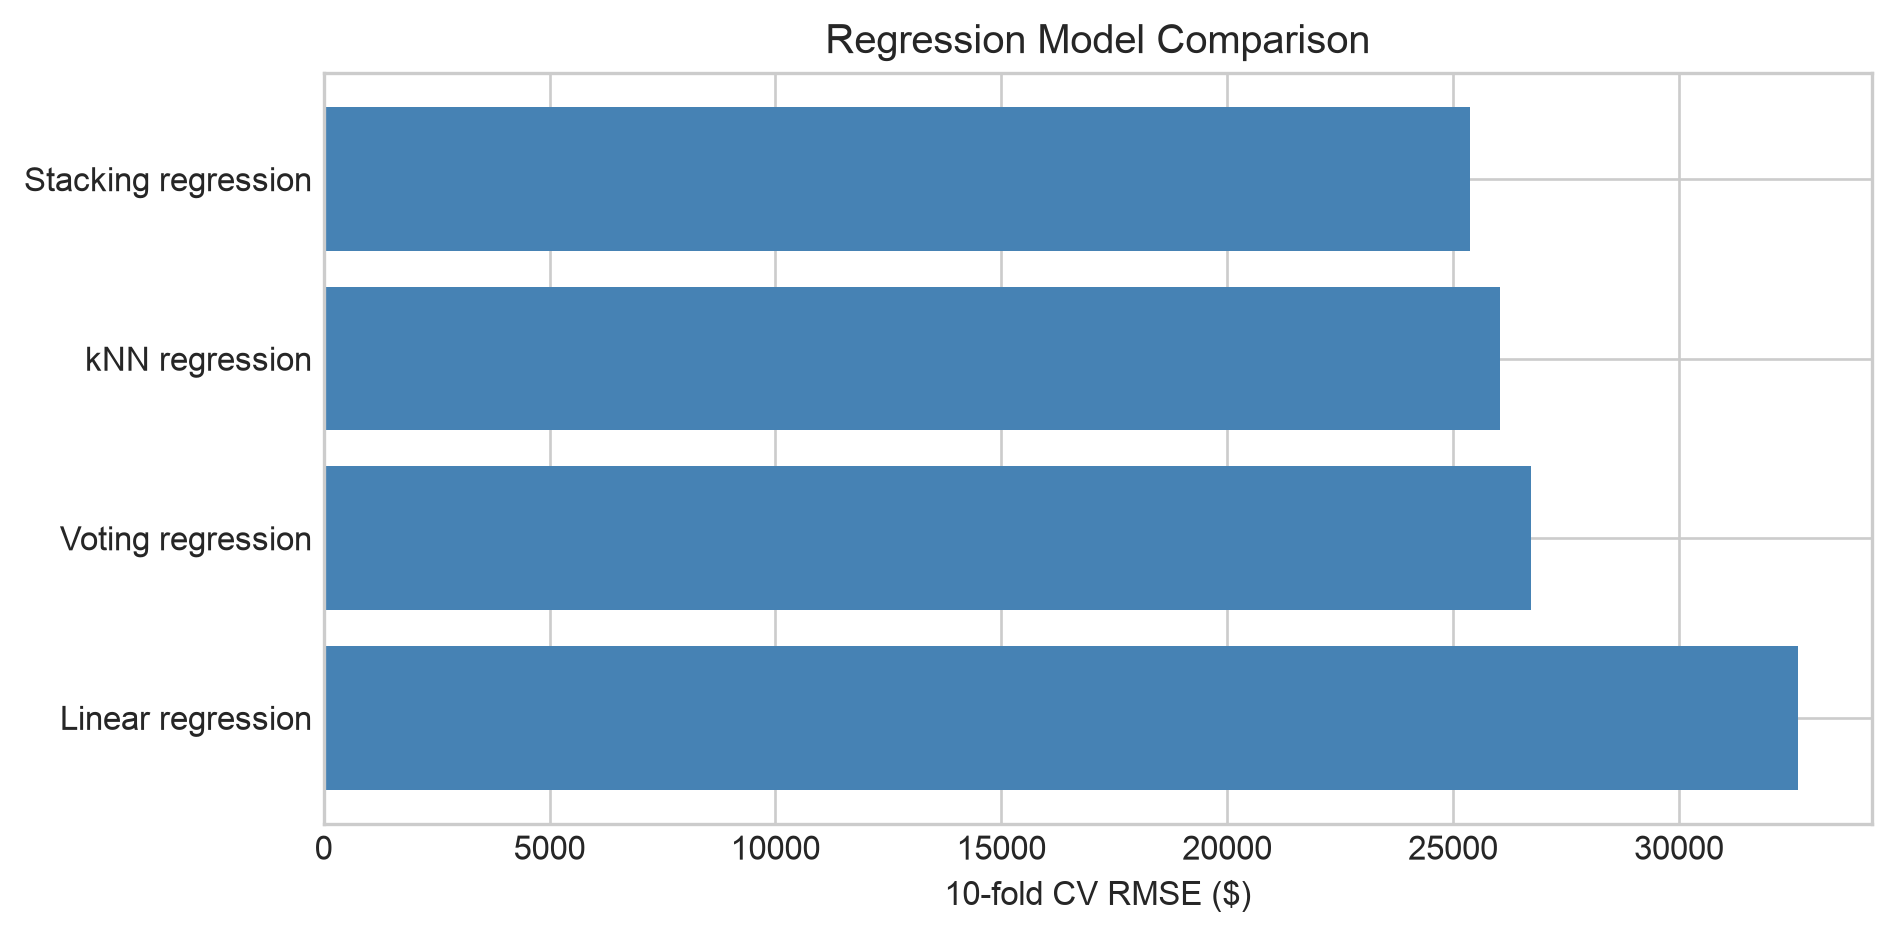

In [23]:
plt.figure(figsize=(8, 4))
plt.barh(
    regression_results["Model"],
    regression_results["CV RMSE"],
    color="steelblue",
)
plt.gca().invert_yaxis()
plt.xlabel("10-fold CV RMSE ($)")
plt.title("Regression Model Comparison")
plt.tight_layout()
plt.show()

The stacking regression worked best because it had the lowest cross-validation RMSE. Its RMSE was about $25,400, compared with about $26,000 for kNN, $26,700 for voting, and $32,600 for linear regression. Stacking helped because it learned how much weight to give the two base models instead of simply averaging them.

## Voting in Classification

Suppose you have three models for predicting a categorical target:

- k-nearest neighbors
- logistic regression
- decision tree

How might you apply voting to create an ensemble model? Discuss conceptually with your partner. Create a concrete example to illustrate your method. Hint: There are two basic approaches to voting in classification; can you think of both?

Note: You can assume a binary target, but the general idea of voting applies to multiclass problems. However, if any of the candidate *models* are not naturally multiclass (like logistic regression) then you have to consider things like OvR and OvO as we have discussed.

### Response

There are two basic ways to use voting for classification:

- **Hard voting:** Each model predicts a class, and the class with the most votes wins. For example, suppose kNN predicts `1`, logistic regression predicts `1`, and the decision tree predicts `0`. The voting model predicts `1` because it received two of the three votes.
- **Soft voting:** Each model gives a probability for each class, and the probabilities are averaged. For example, suppose the three probabilities for class `1` are 0.70, 0.60, and 0.35. Their average is 0.55, so the voting model predicts class `1`.

Soft voting uses more information because it considers how confident each model is, not only its final class prediction.

## Choose your own Classification

**Working together with your partner**, choose an interesting data set to fit *classification* models for, that is, a data set with a *categorical* target variable and several feature variables. Could be a data set that: we have used in class, we have used on an assignment, a data set from your project, you used in another course, or you just find interesting! You'll work together with your partner to develop *classification* models to predict the *categorical* target (so you need to decide on the data set and target variable together with your partner).

After you have decided on the data set and target variable:

- One partner should fit a k-nearest neighbors classification model
- One partner should fit another classification model like decision tree or logistic regression

If you're using an example from earlier in the class, you can use a model you have already come up with or you can try something new. Note: you do NOT have to agree on the features included in your models.

After each partner has their model, **work together to combine your code and create an ensemble model that uses *voting***.

For each of the three models (knn classification, other classification, voting ensemble)

1. Fit the model using the training data
1. Use the fitted model to predict the target for a few observations of your choice, and compare the predictions
1. Estimate the test macro precision, recall, and F1 score using cross-validation, and compare the results

Which model seems to work best?

**Hint:** [`VotingClassifier`](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.VotingClassifier.html) works almost identically to `VotingRegressor`.


### Target and training data

I am using the Ames Housing data again. I created a binary target where `1` means the home sold above the median price of $160,000 and `0` means it sold at or below the median. This makes the two classes close to balanced. `SalePrice` is not included as a predictor.

In [24]:
median_sale_price = y_regression.median()
y_classification = (y_regression > median_sale_price).astype(int)
X_classification = houses[features]

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_classification,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification,
)

print(f"Median sale price: ${median_sale_price:,.0f}")
print("Class counts:")
y_classification.value_counts().sort_index().rename(
    index={0: "At or below median", 1: "Above median"}
)

Median sale price: $160,000
Class counts:


SalePrice
At or below median    1466
Above median          1459
Name: count, dtype: int64

In [25]:
def make_classification_model(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
        ("model", model),
    ])


knn_classification_search = GridSearchCV(
    make_classification_model(KNeighborsClassifier()),
    {
        "model__n_neighbors": list(range(3, 32, 2)),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    cv=10,
    scoring="f1_macro",
)
knn_classification_search.fit(X_class_train, y_class_train)

best_classification_k = knn_classification_search.best_params_["model__n_neighbors"]
best_classification_weights = knn_classification_search.best_params_["model__weights"]
best_classification_p = knn_classification_search.best_params_["model__p"]
knn_classification_model = make_classification_model(
    KNeighborsClassifier(
        n_neighbors=best_classification_k,
        weights=best_classification_weights,
        p=best_classification_p,
    )
)
logistic_model = make_classification_model(
    LogisticRegression(max_iter=5000)
)

voting_classification_model = VotingClassifier(
    estimators=[
        ("knn", knn_classification_model),
        ("logistic", logistic_model),
    ],
    voting="soft",
)

classification_models = {
    "kNN classification": knn_classification_model,
    "Logistic regression": logistic_model,
    "Soft voting": voting_classification_model,
}

for model in classification_models.values():
    model.fit(X_class_train, y_class_train)

print("Best kNN settings:", knn_classification_search.best_params_)

Best kNN settings: {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'distance'}


### Predictions for a few homes

In [26]:
classification_examples = X_class_test.iloc[:5]

classification_predictions = pd.DataFrame({
    "Actual class": y_class_test.loc[classification_examples.index]
})

for name, model in classification_models.items():
    classification_predictions[name] = model.predict(classification_examples)

classification_predictions

,Actual class,kNN classification,Logistic regression,Soft voting
2052,1,1,0,1
115,1,1,1,1
782,0,0,1,1
2662,0,1,0,0
2884,1,1,1,1


### Cross-validation precision, recall, and F1

In [27]:
classification_cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42,
)

classification_scoring = {
    "Macro precision": "precision_macro",
    "Macro recall": "recall_macro",
    "Macro F1": "f1_macro",
}

classification_rows = []

for name, model in classification_models.items():
    scores = cross_validate(
        model,
        X_class_train,
        y_class_train,
        cv=classification_cv,
        scoring=classification_scoring,
        n_jobs=-1,
    )
    classification_rows.append({
        "Model": name,
        **{
            metric: scores["test_" + metric].mean()
            for metric in classification_scoring
        },
    })

classification_results = (
    pd.DataFrame(classification_rows)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)
classification_results.round(3)

,Model,Macro precision,Macro recall,Macro F1
0,Soft voting,0.925,0.924,0.924
1,Logistic regression,0.918,0.918,0.917
2,kNN classification,0.917,0.915,0.915


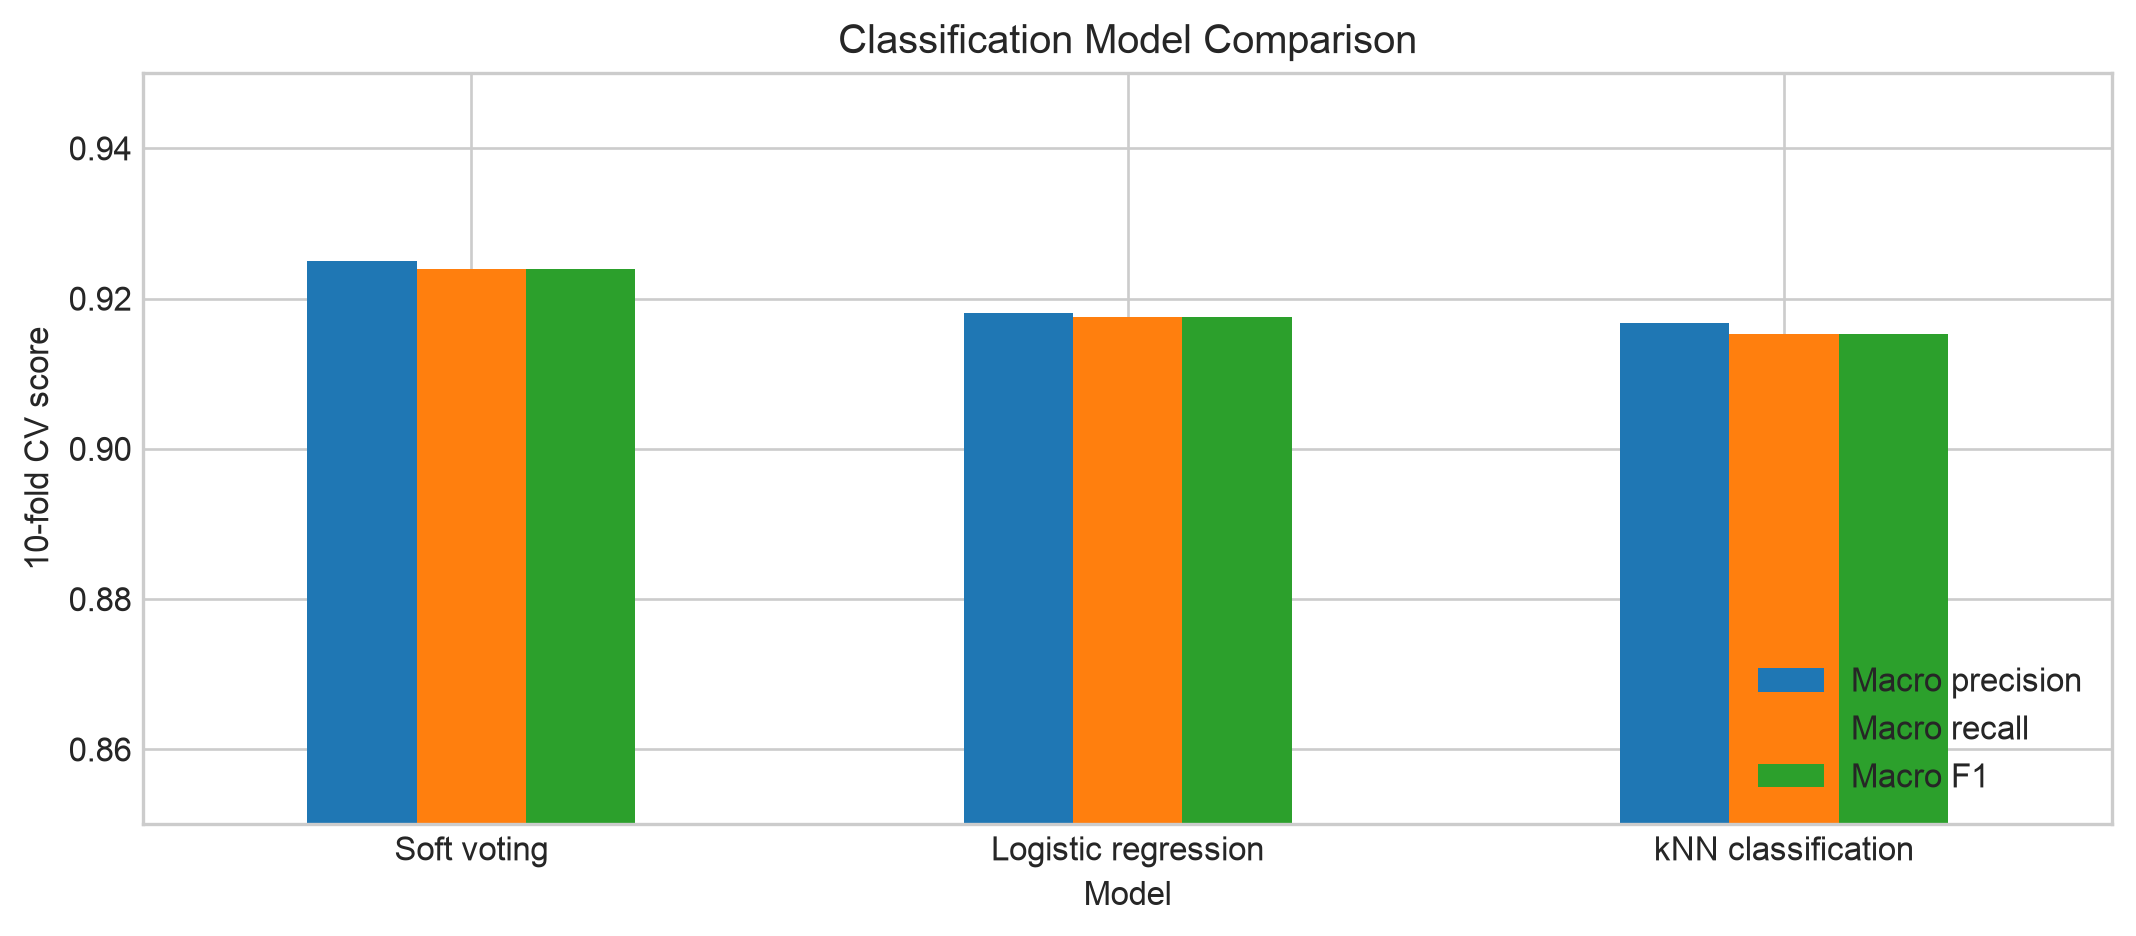

In [28]:
classification_results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 4),
    ylim=(0.85, 0.95),
    rot=0,
)
plt.ylabel("10-fold CV score")
plt.title("Classification Model Comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The soft-voting model worked best. Its macro precision was about 0.925, and its macro recall and F1 were about 0.924. The individual models were close to 0.92, but averaging their probabilities gave a small improvement.

## Final conclusion

For regression, stacking performed best because it combined the strengths of linear regression and kNN. For classification, soft voting performed best because it averaged the probability estimates from kNN and logistic regression. In both parts, the ensemble gave a small improvement over the individual models.